# Iris Flower Classification Using Machine Learning

## 1. Project Idea

This project uses machine learning to predict the species of an Iris flower from four measurements: sepal length, sepal width, petal length, and petal width.

The model classifies flowers into three species: Iris setosa, Iris versicolor, and Iris virginica.

This project demonstrates how supervised machine learning can learn patterns from labelled data and use those patterns to classify new observations. Comparing two classification algorithms also helps us understand how different models perform on the same dataset.

## Objectives
- Load and inspect a dataset.
- Check for missing values.
- Prepare the features and target variable.
- Train a Decision Tree and a K-Nearest Neighbors classifier.
- Compare model accuracy and confusion matrices.
- Identify the better-performing model on the test set.

In [1]:

# Import libraries and load the Iris dataset

import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()

# Features: measurements used to make predictions
X = pd.DataFrame(iris.data, columns=iris.feature_names)

# Target: species labels we want to predict
y = iris.target

# Display the first five rows
print("First five rows of the dataset:")
display(X.head())

print("Dataset shape:", X.shape)
print("Target classes:", iris.target_names)


First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Dataset shape: (150, 4)
Target classes: ['setosa' 'versicolor' 'virginica']


In [2]:

# Check for missing values
print("Missing values in each feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

# Check for duplicate rows
print("Duplicate feature rows:", X.duplicated().sum())

# Check target distribution
print("\nNumber of samples in each species:")
print(pd.Series(y).value_counts().sort_index())

# Check the feature and target dimensions
print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


Missing values in each feature:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Total missing values: 0
Duplicate feature rows: 1

Number of samples in each species:
0    50
1    50
2    50
Name: count, dtype: int64

Feature shape: (150, 4)
Target shape: (150,)


In [3]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [4]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Model 1: Decision Tree
decision_tree = DecisionTreeClassifier(random_state=42)

# Model 2: K-Nearest Neighbors
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train both models
decision_tree.fit(X_train, y_train)
knn.fit(X_train, y_train)

print("Both models have been trained successfully!")


Both models have been trained successfully!


Decision Tree Accuracy: 93.33%


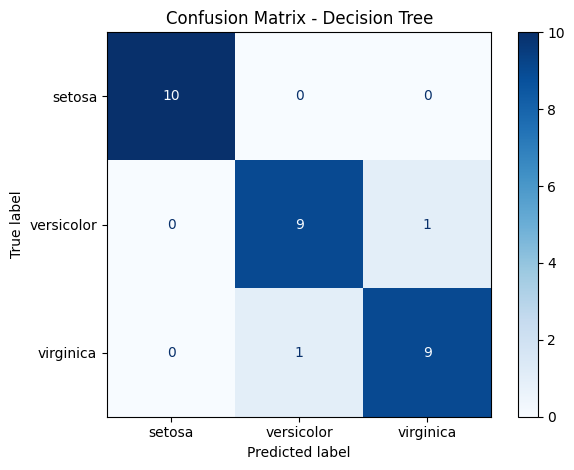

KNN Accuracy: 93.33%


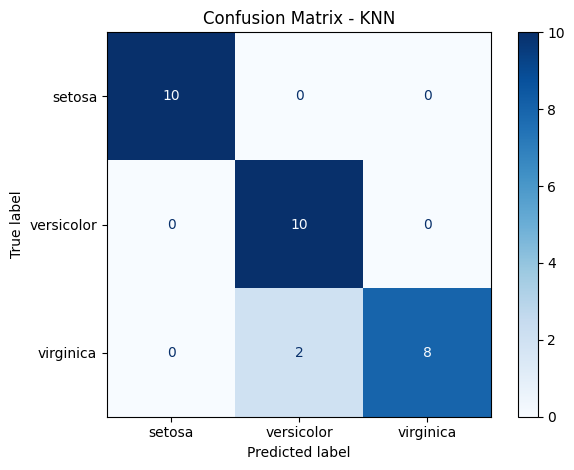


Model comparison:
Decision Tree: 93.3333%
KNN: 93.3333%

Result: Both models achieved the same accuracy.


In [6]:

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "Decision Tree": decision_tree,
    "KNN": knn
}

scores = {}

for name, model in models.items():
    # Predict species for the test data
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    scores[name] = accuracy

    print(f"{name} Accuracy: {accuracy:.2%}")

    # Display confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=iris.target_names,
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

# Identify the model with the higher accuracy
best_model = max(scores, key=scores.get)


print("\nModel comparison:")
for name, score in scores.items():
    print(f"{name}: {score:.4%}")

best_score = max(scores.values())
best_models = [
    name for name, score in scores.items()
    if score == best_score
]

if len(best_models) == 2:
    print("\nResult: Both models achieved the same accuracy.")
else:
    print("\nBetter-performing model:", best_models[0])




## Conclusion

In this project, I built and evaluated two supervised machine learning models: Decision Tree and K-Nearest Neighbors (KNN), using the Iris flower dataset.

The dataset was inspected for missing values, and its features and target labels were prepared. The dataset was then divided into training and testing sets to evaluate how well the models generalize to unseen observations.

Both Decision Tree and KNN achieved an accuracy of 93.33%. Based on the test-set accuracy, both models performed equally in this experiment.

The confusion matrices helped identify correct predictions and any classification errors for each species.

Through this project, I learned how to prepare a dataset, train machine learning models, evaluate classification performance, and compare different algorithms. One limitation is that the experiment uses a small, well-known dataset, so its results may not represent performance on more complex real-world data.